K-Means


Implement the K-Means clustering algorithm and analyze its performance by varying the number of 
clusters (k) and comparing the results. 

In [2]:
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_samples,silhouette_score
from sklearn.cluster import KMeans


In [3]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

In [4]:
#Generating the sample data from make_blobs
#This particular setting has ...

X,y = make_blobs(n_samples=500,
                 n_features=2,
                 centers=4,
                 cluster_std=1,
                 center_box=(-10.0,10.0),
                 shuffle=True,
                 random_state=1) #For reproducibility

range_n_clusters = [2,3,4,5,6]

In [5]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        init='k-means++',
        random_state=0,
        n_init=10
    )
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

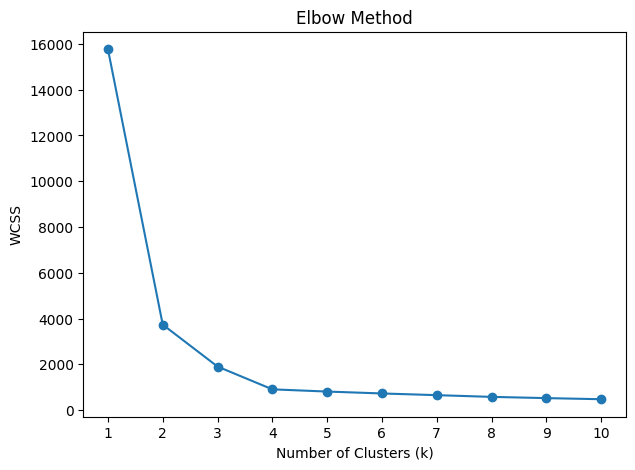

In [6]:
plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
# plt.grid(True)
plt.show()

k = 2, Silhouette Score = 0.7050


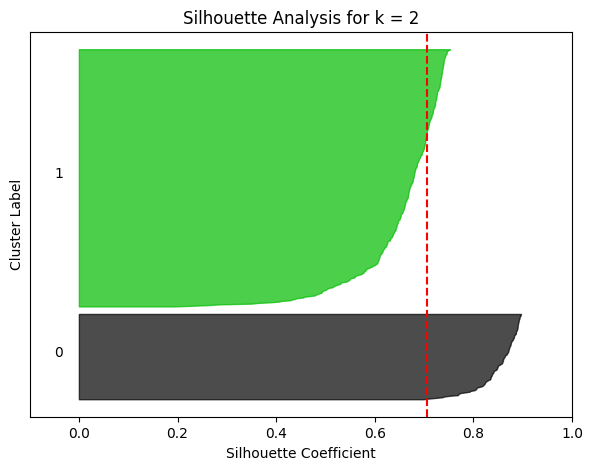

k = 3, Silhouette Score = 0.5882


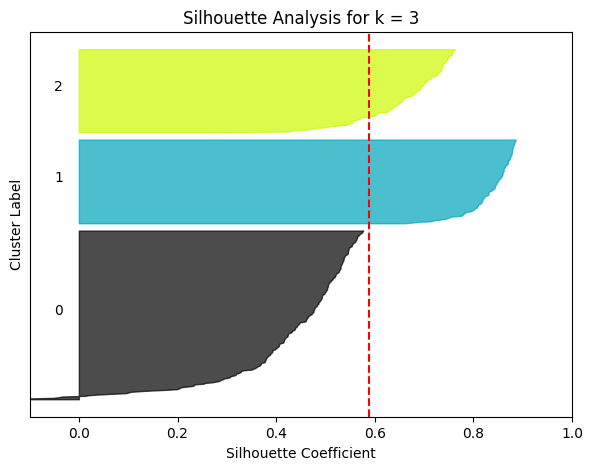

k = 4, Silhouette Score = 0.6505


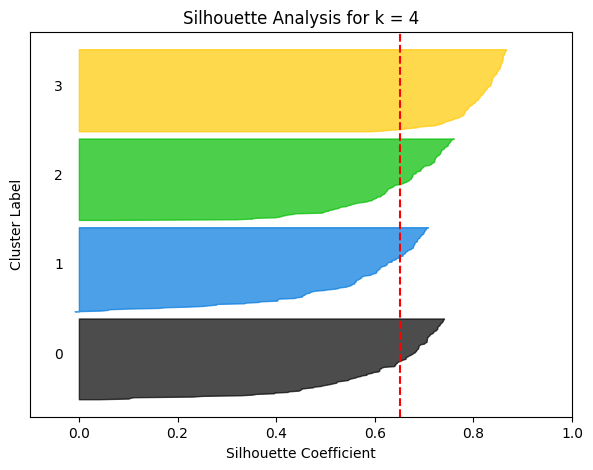

k = 5, Silhouette Score = 0.5747


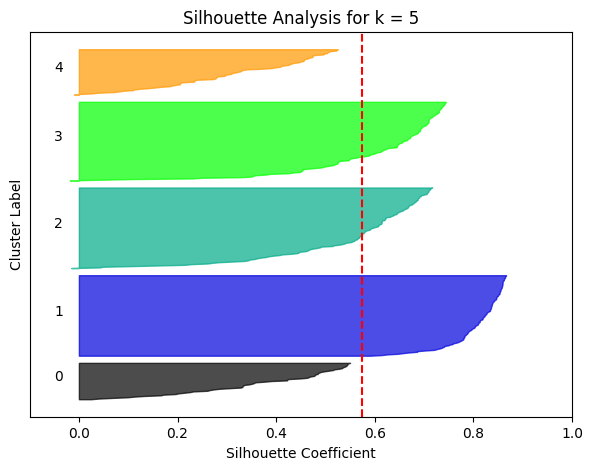

k = 6, Silhouette Score = 0.4548


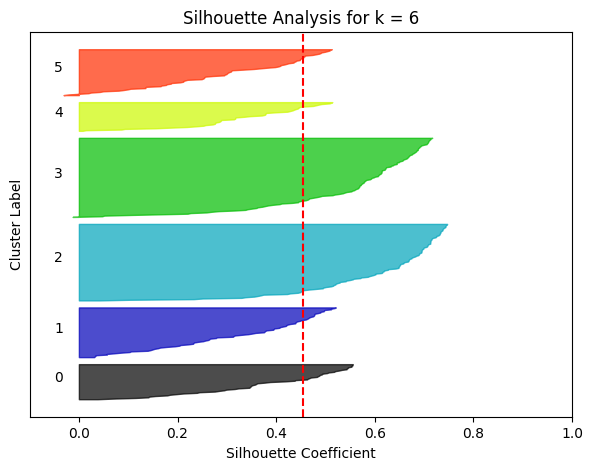

In [7]:
# ---------------- SILHOUETTE ANALYSIS ----------------

range_n_clusters = [2, 3, 4, 5, 6]

for k in range_n_clusters:

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=0,
        n_init=10
    )

    labels = kmeans.fit_predict(X)

    # Average silhouette score
    silhouette_avg = silhouette_score(X, labels)
    print(f"k = {k}, Silhouette Score = {silhouette_avg:.4f}")

    # Individual silhouette scores
    sample_values = silhouette_samples(X, labels)

    plt.figure(figsize=(7, 5))
    y_lower = 10

    for i in range(k):
        values = sample_values[labels == i]
        values.sort()

        size = len(values)
        y_upper = y_lower + size

        color = cm.nipy_spectral(float(i) / k)

        plt.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7
        )

        plt.text(-0.05, y_lower + size / 2, str(i))
        y_lower = y_upper + 10

    plt.axvline(
        x=silhouette_avg,
        color="red",
        linestyle="--"
    )

    plt.title(f"Silhouette Analysis for k = {k}")
    plt.xlabel("Silhouette Coefficient")
    plt.ylabel("Cluster Label")
    plt.xlim([-0.1, 1])
    plt.yticks([])
    plt.show()

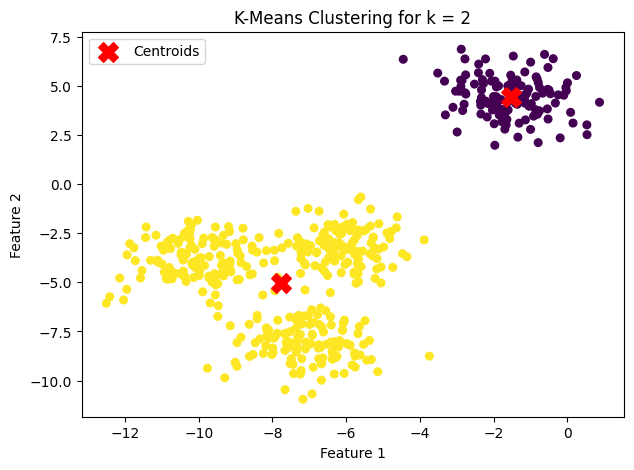

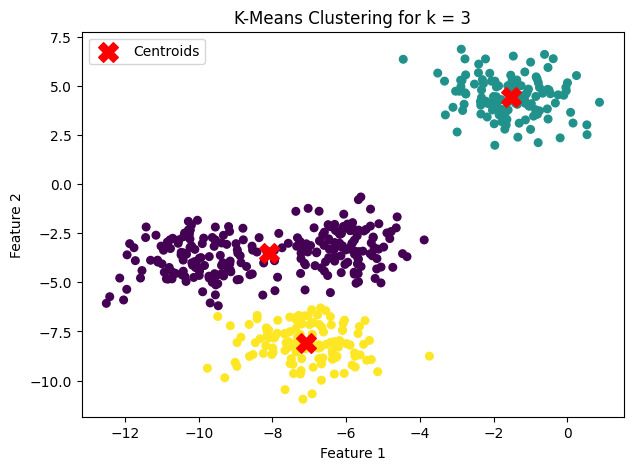

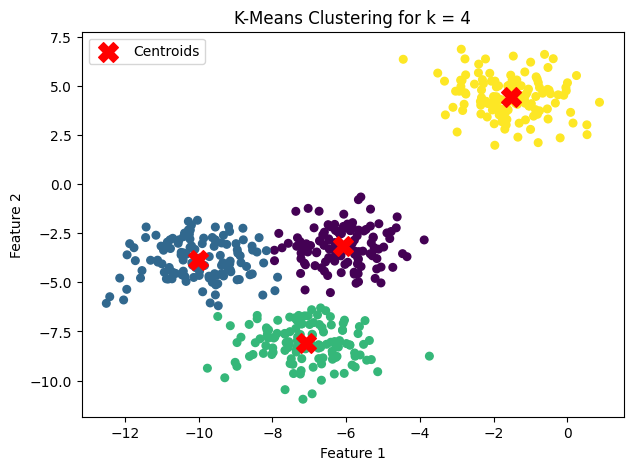

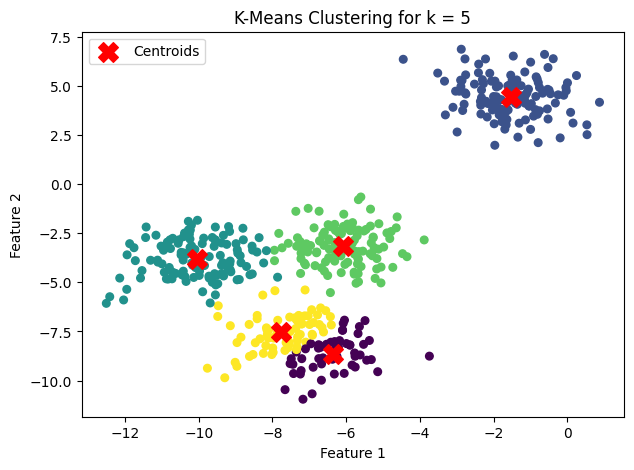

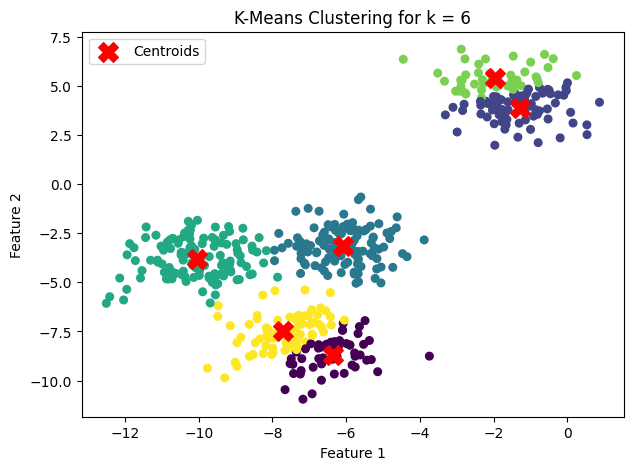

In [8]:
# ---------------- CLUSTER VISUALIZATION ----------------

range_n_clusters = [2, 3, 4, 5, 6]

for k in range_n_clusters:

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=0,
        n_init=10
    )

    labels = kmeans.fit_predict(X)
    centers = kmeans.cluster_centers_

    # Plot data points
    plt.figure(figsize=(7, 5))

    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=labels,
        cmap='viridis',
        s=30
    )

    # Plot cluster centers
    plt.scatter(
        centers[:, 0],
        centers[:, 1],
        c='red',
        marker='X',
        s=200,
        label='Centroids'
    )

    plt.title(f"K-Means Clustering for k = {k}")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.legend()
    plt.show()

In [13]:
for i in range(2, 11):
    model = KMeans(
        n_clusters=i,
        init='k-means++',
        random_state=0,
        n_init=10
    )

    #Assign each data point to a cluster
    cluster_labels = model.fit_predict(X)
    wcss.append(kmeans.inertia_)

    score=silhouette_score(X,cluster_labels)

    print(
        f"Clusters: {i},"
        f"Silhouette score: {score:.4f}"
    )

Clusters: 2,Silhouette score: 0.7050
Clusters: 3,Silhouette score: 0.5882
Clusters: 4,Silhouette score: 0.6505
Clusters: 5,Silhouette score: 0.5747
Clusters: 6,Silhouette score: 0.4548
Clusters: 7,Silhouette score: 0.3638
Clusters: 8,Silhouette score: 0.3316
Clusters: 9,Silhouette score: 0.3354
Clusters: 10,Silhouette score: 0.3397
